# Predicting customer buying behaviour

**Task:** use the British Airways customer-booking data to identify which customers are likely
to complete a booking, quantify how predictive the data really is, and explain which variables
drive the model.

This notebook is the reproducible analysis behind the one-slide summary.
It is written in percent format (`# %%` cells), so the same file can run as a script or be
converted to a Jupyter notebook.

## 1. Setup and helper functions

In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Make paths work whether the file is run as a script or as a notebook.
ROOT = Path.cwd()
if not (ROOT / "customer_booking.csv").exists():
    if "__file__" in globals():
        ROOT = Path(__file__).resolve().parents[1]
    else:
        ROOT = ROOT.parent
DATA_PATH = ROOT / "customer_booking.csv"
OUT_DIR = ROOT / "outputs"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

# Consistent visual language for notebook and slide.
NAVY = "#0B1F3A"
BLUE = "#1F4E79"
MID_BLUE = "#2E75B6"
LIGHT_BLUE = "#9DC3E6"
PALE_BLUE = "#DDEBF7"
TEAL = "#008C95"
ORANGE = "#E67E22"
GREEN = "#1E8449"
RED = "#C0392B"
GREY = "#6B7280"
LIGHT_GREY = "#E5E7EB"
OFF_WHITE = "#F7F9FC"

plt.rcParams.update(
    {
        "font.family": "Segoe UI",
        "axes.edgecolor": "#CBD5E1",
        "axes.labelcolor": NAVY,
        "axes.titlecolor": NAVY,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.color": "#475569",
        "ytick.color": "#475569",
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "grid.color": "#E2E8F0",
        "grid.linewidth": 0.8,
        "savefig.facecolor": "white",
    }
)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_ESTIMATORS = 600
MIN_SAMPLES_LEAF = 10


def save_figure(fig: plt.Figure, filename: str) -> None:
    """Save a figure for the slide deck and show it in the notebook."""
    fig.savefig(FIG_DIR / filename, dpi=200, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def clean_axes(ax: plt.Axes, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid_axis, alpha=0.7)
    ax.set_axisbelow(True)


def pct(value: float, decimals: int = 1) -> str:
    return f"{value * 100:.{decimals}f}%"

## 2. Load the data and check quality

The raw file contains 50,000 rows and 14 columns. There are no missing values, but there are
**719 exact duplicate rows**. We remove these so that identical profiles are not counted twice
during training and validation. This leaves 49,281 rows.

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="ISO-8859-1")
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Missing values: {int(raw.isna().sum().sum())}")
print(f"Exact duplicate rows: {int(raw.duplicated().sum()):,}")

booking = raw.drop_duplicates().reset_index(drop=True)
print(f"Analysis shape: {booking.shape[0]:,} rows x {booking.shape[1]} columns")
print(f"Overall booking rate: {pct(booking['booking_complete'].mean())}")
booking.head()

Raw shape: 50,000 rows x 14 columns
Missing values: 0
Exact duplicate rows: 719
Analysis shape: 49,281 rows x 14 columns
Overall booking rate: 15.0%


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


### Data dictionary

| Column | Meaning |
|---|---|
| `num_passengers` | Number of passengers on the booking |
| `sales_channel` | Internet or Mobile |
| `trip_type` | Round trip, one way or circle trip |
| `purchase_lead` | Days between booking and departure |
| `length_of_stay` | Days spent at the destination |
| `flight_hour` | Departure hour (0-23) |
| `flight_day` | Day of week of departure |
| `route` | Origin and destination airport codes |
| `booking_origin` | Country where the booking was made |
| `wants_extra_baggage` | Extra baggage selected |
| `wants_preferred_seat` | Preferred seat selected |
| `wants_in_flight_meals` | In-flight meals selected |
| `flight_duration` | Flight duration in hours |
| `booking_complete` | **Target:** 1 if the booking was completed |

The target is imbalanced: only 15% of enquiries become bookings. Accuracy alone is therefore
misleading, so we focus on ROC-AUC, PR-AUC, lift and recall/precision at a chosen threshold.

In [3]:
summary = (
    booking.describe(include="all")
    .T.assign(missing=lambda d: booking.isna().sum())
    .loc[
        :,
        [
            "count",
            "missing",
            "unique",
            "mean",
            "std",
            "min",
            "50%",
            "max",
        ],
    ]
)
summary

,count,missing,unique,mean,std,min,50%,max
num_passengers,49281.0,0,NaN,1.590187,1.016538,1.0,1.0,9.0
sales_channel,49281,0,2,NaN,NaN,NaN,NaN,NaN
trip_type,49281,0,3,NaN,NaN,NaN,NaN,NaN
purchase_lead,49281.0,0,NaN,84.723281,90.410229,0.0,51.0,867.0
length_of_stay,49281.0,0,NaN,23.053976,33.832149,0.0,17.0,778.0
flight_hour,49281.0,0,NaN,9.070676,5.413099,0.0,9.0,23.0
flight_day,49281,0,7,NaN,NaN,NaN,NaN,NaN
route,49281,0,799,NaN,NaN,NaN,NaN,NaN
booking_origin,49281,0,104,NaN,NaN,NaN,NaN,NaN
wants_extra_baggage,49281.0,0,NaN,0.668229,0.470854,0.0,1.0,1.0


### Target balance

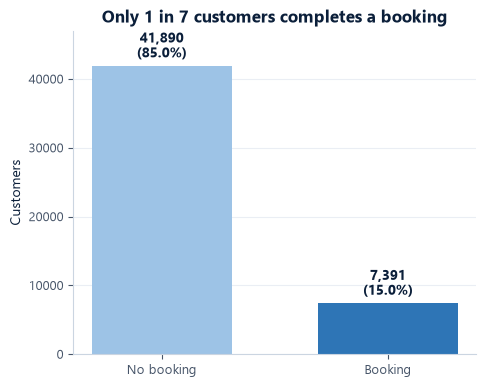

In [4]:
target_counts = booking["booking_complete"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
colors = [LIGHT_BLUE, MID_BLUE]
bars = ax.bar(["No booking", "Booking"], target_counts.values, color=colors, width=0.62)
for bar, count in zip(bars, target_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 700,
        f"{count:,}\n({count / len(booking):.1%})",
        ha="center",
        va="bottom",
        fontsize=10,
        color=NAVY,
        fontweight="bold",
    )
ax.set_ylim(0, 47000)
ax.set_ylabel("Customers")
ax.set_title("Only 1 in 7 customers completes a booking")
clean_axes(ax)
save_figure(fig, "01_target_balance.png")

## 3. Exploratory analysis: what separates bookers from non-bookers?

We look at the raw variables before modelling. These are descriptive relationships, not causal
effects, but they tell us where the model is likely to find signal.

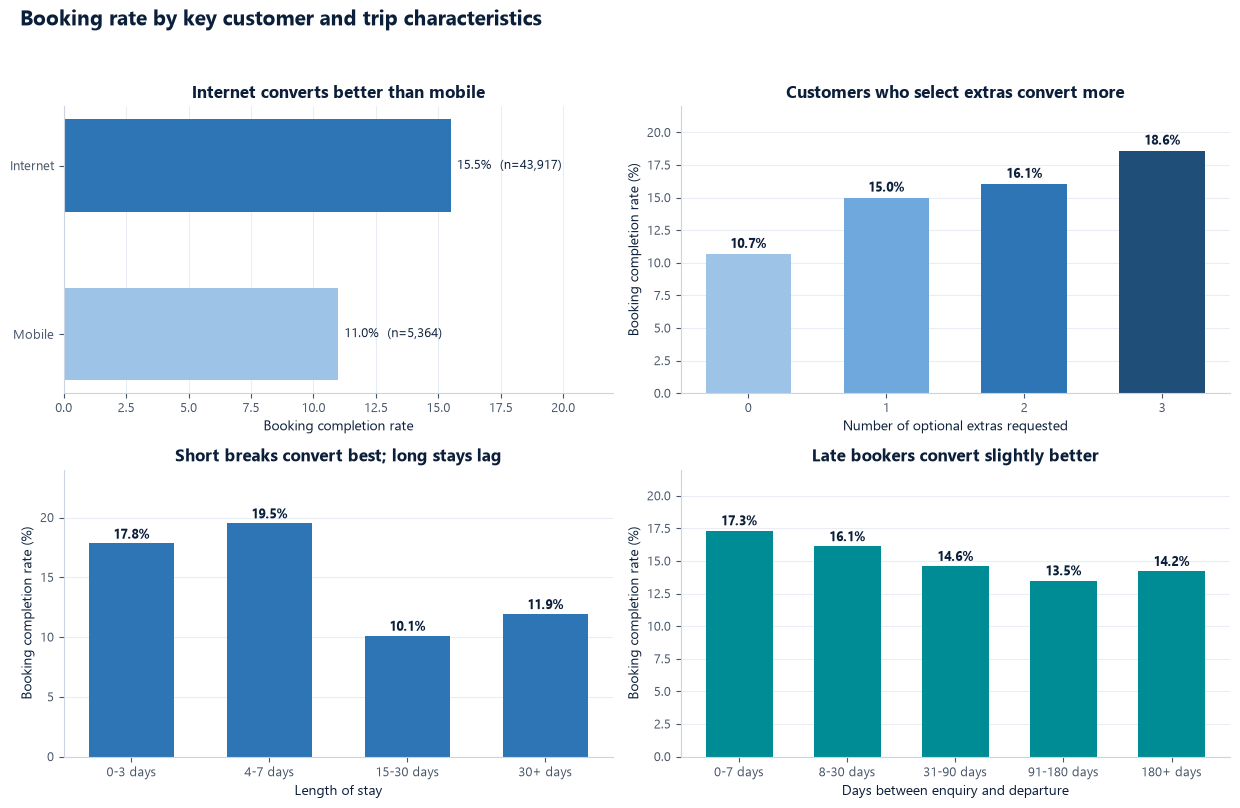

In [5]:
booking = booking.assign(
    extras_count=booking[
        ["wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]
    ].sum(axis=1),
    lead_bucket=pd.cut(
        booking["purchase_lead"],
        bins=[-1, 7, 30, 90, 180, 10_000],
        labels=["0-7 days", "8-30 days", "31-90 days", "91-180 days", "180+ days"],
    ),
    stay_bucket=pd.cut(
        booking["length_of_stay"],
        bins=[-1, 3, 7, 14, 30, 10_000],
        labels=["0-3 days", "4-7 days", "8-14 days", "15-30 days", "30+ days"],
    ),
)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))

# Booking rate by sales channel and trip type
channel = (
    booking.groupby("sales_channel", observed=True)["booking_complete"]
    .agg(["mean", "count"])
    .sort_values("mean")
)
ax = axes[0, 0]
bars = ax.barh(channel.index, channel["mean"] * 100, color=[LIGHT_BLUE, MID_BLUE], height=0.55)
for bar, (rate, count) in zip(bars, channel[["mean", "count"]].values):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{rate * 100:.1f}%  (n={count:,.0f})",
        va="center",
        fontsize=9,
        color=NAVY,
    )
ax.set_xlim(0, 22)
ax.set_xlabel("Booking completion rate")
ax.set_title("Internet converts better than mobile")
clean_axes(ax, "x")

# Booking rate by number of extras requested
extras = (
    booking.groupby("extras_count", observed=True)["booking_complete"]
    .agg(["mean", "count"])
    .reset_index()
)
ax = axes[0, 1]
ax.bar(extras["extras_count"], extras["mean"] * 100, color=[LIGHT_BLUE, "#6FA8DC", MID_BLUE, BLUE], width=0.62)
for x, rate, count in zip(extras["extras_count"], extras["mean"], extras["count"]):
    ax.text(x, rate * 100 + 0.45, f"{rate * 100:.1f}%", ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_xticks(extras["extras_count"])
ax.set_xlabel("Number of optional extras requested")
ax.set_ylabel("Booking completion rate (%)")
ax.set_ylim(0, 22)
ax.set_title("Customers who select extras convert more")
clean_axes(ax)

# Booking rate by length-of-stay bucket
stay = (
    booking.groupby("stay_bucket", observed=True)["booking_complete"]
    .agg(["mean", "count"])
    .reset_index()
)
ax = axes[1, 0]
ax.bar(stay["stay_bucket"].astype(str), stay["mean"] * 100, color=MID_BLUE, width=0.62)
for x, rate in enumerate(stay["mean"]):
    ax.text(x, rate * 100 + 0.4, f"{rate * 100:.1f}%", ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_xlabel("Length of stay")
ax.set_ylabel("Booking completion rate (%)")
ax.set_ylim(0, 24)
ax.set_title("Short breaks convert best; long stays lag")
clean_axes(ax)

# Booking rate by purchase lead-time bucket
lead = (
    booking.groupby("lead_bucket", observed=True)["booking_complete"]
    .agg(["mean", "count"])
    .reset_index()
)
ax = axes[1, 1]
ax.bar(lead["lead_bucket"].astype(str), lead["mean"] * 100, color=TEAL, width=0.62)
for x, rate in enumerate(lead["mean"]):
    ax.text(x, rate * 100 + 0.4, f"{rate * 100:.1f}%", ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_xlabel("Days between enquiry and departure")
ax.set_ylabel("Booking completion rate (%)")
ax.set_ylim(0, 22)
ax.set_title("Late bookers convert slightly better")
clean_axes(ax)

fig.suptitle("Booking rate by key customer and trip characteristics", x=0.02, ha="left", fontsize=15, fontweight="bold", color=NAVY)
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(fig, "02_booking_rate_drivers.png")

### Geography is the strongest descriptive signal

Australia supplies 36% of all enquiries but only 5.1% convert. Malaysia converts 34.5%,
Indonesia 26.3%, Thailand 23.3% and Vietnam 29.5%. The mix of source markets therefore has a
very large effect on the overall conversion rate and on how the model scores customers.

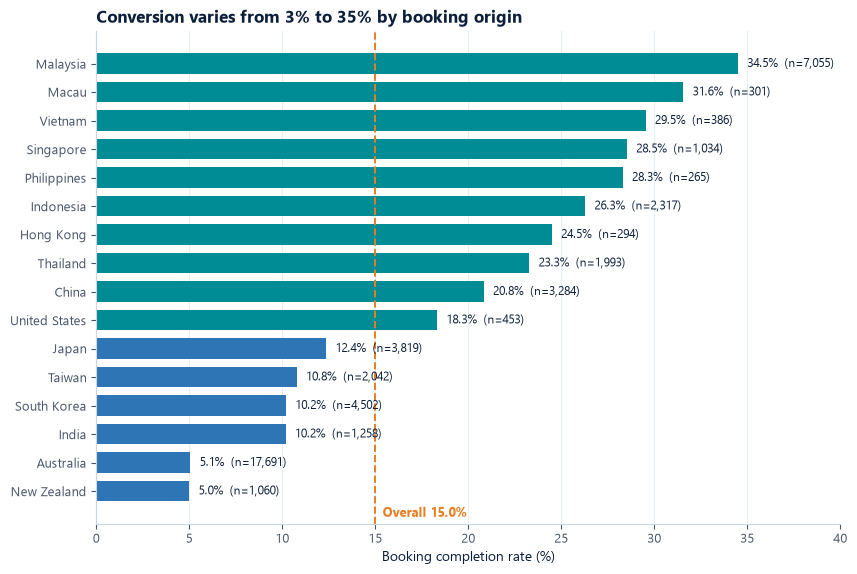

In [6]:
origin = (
    booking.groupby("booking_origin", observed=True)["booking_complete"]
    .agg(["mean", "count"])
    .query("count >= 250")
    .sort_values("mean", ascending=True)
)
fig, ax = plt.subplots(figsize=(9.6, 6.4))
colors = [MID_BLUE if v < booking["booking_complete"].mean() else TEAL for v in origin["mean"]]
bars = ax.barh(origin.index, origin["mean"] * 100, color=colors, height=0.72)
for bar, (rate, count) in zip(bars, origin[["mean", "count"]].values):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{rate * 100:.1f}%  (n={count:,.0f})",
        va="center",
        fontsize=8.5,
        color=NAVY,
    )
ax.axvline(booking["booking_complete"].mean() * 100, color=ORANGE, linestyle="--", linewidth=1.4)
ax.text(
    booking["booking_complete"].mean() * 100 + 0.4,
    -0.9,
    f"Overall {booking['booking_complete'].mean():.1%}",
    color=ORANGE,
    fontsize=9,
    fontweight="bold",
)
ax.set_xlim(0, 40)
ax.set_xlabel("Booking completion rate (%)")
ax.set_title("Conversion varies from 3% to 35% by booking origin", loc="left")
clean_axes(ax, "x")
save_figure(fig, "03_origin_conversion.png")

### Correlation structure

Numeric correlations with the target are weak (all below 0.11 in absolute value). The signal is
mostly non-linear and interaction-driven, which is why a tree-based model is appropriate.

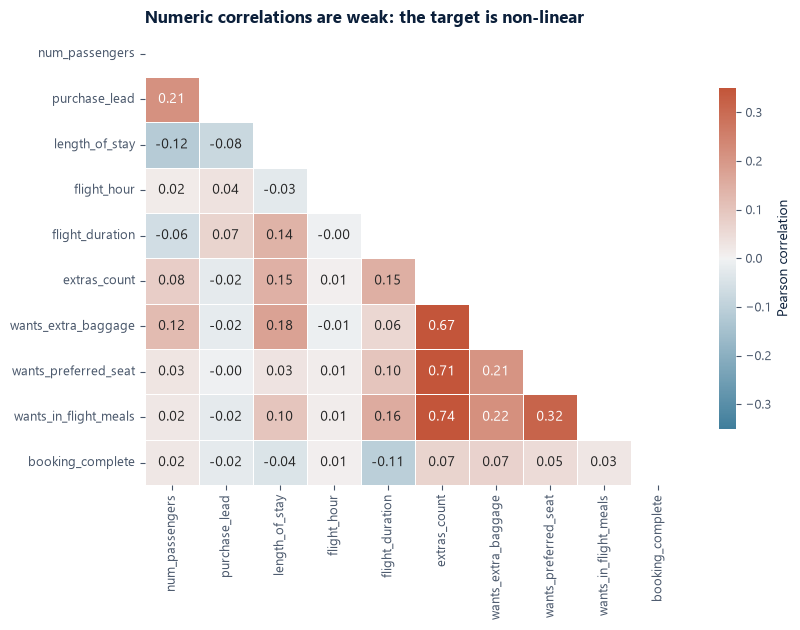

In [7]:
numeric_for_corr = [
    "num_passengers",
    "purchase_lead",
    "length_of_stay",
    "flight_hour",
    "flight_duration",
    "extras_count",
    "wants_extra_baggage",
    "wants_preferred_seat",
    "wants_in_flight_meals",
    "booking_complete",
]
corr = booking[numeric_for_corr].corr()
fig, ax = plt.subplots(figsize=(8.4, 6.4))
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(
    corr,
    mask=mask,
    cmap=cmap,
    vmin=-0.35,
    vmax=0.35,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Numeric correlations are weak: the target is non-linear", loc="left")
fig.tight_layout()
save_figure(fig, "04_correlation_heatmap.png")

## 4. Feature engineering

We keep the raw variables and add a small number of interpretable features:

- **Departure hour cycle:** sine/cosine transforms so 23:00 and 00:00 are close together.
- **Weekend flag:** Saturday/Sunday departures may behave differently from weekdays.
- **Extras count:** total optional extras selected (0-3).
- **Day of week numeric:** Monday = 1 ... Sunday = 7.

High-cardinality categoricals (`route` with 799 levels and `booking_origin` with 104) are
**target-encoded out-of-fold** inside the model pipeline. This captures each route's and
market's historic conversion rate without leaking the target into the training rows.

The three "wants" fields deserve a caveat: they are captured during the booking journey. If they
are only recorded at payment, they are contemporaneous with the target and could be leakage. The
notebook includes a sensitivity check without them in Section 8.

In [8]:
DAY_MAP = {"Mon": 1, "Tue": 2, "Wed": 3, "Thu": 4, "Fri": 5, "Sat": 6, "Sun": 7}


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Create model-ready features from the raw booking data."""
    out = df.copy()
    out["flight_day_num"] = out["flight_day"].map(DAY_MAP).astype(int)
    out["is_weekend"] = out["flight_day"].isin(["Sat", "Sun"]).astype(int)
    out["extras_count"] = out[
        ["wants_extra_baggage", "wants_preferred_seat", "wants_in_flight_meals"]
    ].sum(axis=1)
    out["flight_hour_sin"] = np.sin(2 * np.pi * out["flight_hour"] / 24)
    out["flight_hour_cos"] = np.cos(2 * np.pi * out["flight_hour"] / 24)
    return out


model_data = engineer_features(booking)

NUMERIC_FEATURES = [
    "num_passengers",
    "purchase_lead",
    "length_of_stay",
    "flight_hour",
    "flight_hour_sin",
    "flight_hour_cos",
    "flight_duration",
    "flight_day_num",
    "is_weekend",
    "extras_count",
    "wants_extra_baggage",
    "wants_preferred_seat",
    "wants_in_flight_meals",
]
CATEGORICAL_FEATURES = ["sales_channel", "trip_type", "route", "booking_origin"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "booking_complete"

X = model_data[FEATURES]
y = model_data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows ({y_train.mean():.1%} booked)")
print(f"Test:  {len(X_test):,} rows ({y_test.mean():.1%} booked)")

# Save a clean, model-ready dataset for audit and reuse.
model_data.to_csv(OUT_DIR / "customer_booking_features.csv", index=False)

Train: 39,424 rows (15.0% booked)
Test:  9,857 rows (15.0% booked)


## 5. Model training

**Random Forest** is a good fit for this task: it handles non-linear relationships and
interactions, is robust to outliers, and its feature contributions can be explained with
permutation importance. We use:

- 600 trees, minimum 10 observations per leaf (regularisation against overfitting)
- `class_weight="balanced_subsample"` to stop the 85/15 imbalance dominating the trees
- Out-of-fold target encoding for route and booking origin
- 5-fold stratified cross-validation on the training set only

A regularised logistic regression with one-hot encoding is trained as a benchmark.

In [9]:
rf_pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            ColumnTransformer(
                transformers=[
                    ("numeric", "passthrough", NUMERIC_FEATURES),
                    (
                        "categorical",
                        TargetEncoder(
                            target_type="binary",
                            smooth="auto",
                            cv=5,
                            random_state=RANDOM_STATE,
                        ),
                        CATEGORICAL_FEATURES,
                    ),
                ]
            ),
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=MIN_SAMPLES_LEAF,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

start = time.time()
cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=1,
    return_train_score=False,
)
cv_seconds = time.time() - start

cv_table = pd.DataFrame(
    {
        "metric": list(SCORING.keys()),
        "mean": [cv_results[f"test_{m}"].mean() for m in SCORING],
        "std": [cv_results[f"test_{m}"].std() for m in SCORING],
    }
)
cv_table["mean_pm_std"] = cv_table.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
)
print(f"5-fold CV finished in {cv_seconds:.1f}s")
cv_table

5-fold CV finished in 68.9s


,metric,mean,std,mean_pm_std
0,roc_auc,0.794752,0.003488,0.7948 ± 0.0035
1,pr_auc,0.390922,0.011496,0.3909 ± 0.0115
2,accuracy,0.774148,0.003127,0.7741 ± 0.0031
3,precision,0.354811,0.003677,0.3548 ± 0.0037
4,recall,0.617789,0.009794,0.6178 ± 0.0098
5,f1,0.450704,0.003589,0.4507 ± 0.0036


### Benchmark: random forest vs logistic regression

The logistic regression gives us a sanity check. If the random forest is not materially better,
the extra complexity is not justified.

In [10]:
logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            ColumnTransformer(
                transformers=[
                    (
                        "numeric",
                        StandardScaler(),
                        NUMERIC_FEATURES,
                    ),
                    (
                        "categorical",
                        OneHotEncoder(
                            handle_unknown="infrequent_if_exist",
                            min_frequency=50,
                            sparse_output=False,
                        ),
                        CATEGORICAL_FEATURES,
                    ),
                ]
            ),
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                solver="lbfgs",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

log_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"},
    n_jobs=1,
)

comparison = pd.DataFrame(
    {
        "Model": ["Logistic regression", "Random forest"],
        "CV ROC-AUC": [
            log_cv_results["test_roc_auc"].mean(),
            cv_results["test_roc_auc"].mean(),
        ],
        "CV PR-AUC": [
            log_cv_results["test_pr_auc"].mean(),
            cv_results["test_pr_auc"].mean(),
        ],
        "CV F1": [
            log_cv_results["test_f1"].mean(),
            cv_results["test_f1"].mean(),
        ],
    }
)
comparison

,Model,CV ROC-AUC,CV PR-AUC,CV F1
0,Logistic regression,0.779764,0.353848,0.424797
1,Random forest,0.794752,0.390922,0.450704


### Fit the final model and score the holdout set

The holdout set was untouched during cross-validation and model selection, so these numbers are
an unbiased estimate of performance on new customers.

In [11]:
start = time.time()
rf_pipeline.fit(X_train, y_train)
fit_seconds = time.time() - start

y_proba = rf_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
prevalence = float(y_test.mean())

holdout = {
    "roc_auc": float(roc_auc_score(y_test, y_proba)),
    "pr_auc": float(average_precision_score(y_test, y_proba)),
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1": float(f1_score(y_test, y_pred, zero_division=0)),
    "brier": float(brier_score_loss(y_test, y_proba)),
    "prevalence": prevalence,
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "fit_seconds": round(fit_seconds, 1),
    "cv_seconds": round(cv_seconds, 1),
}

# Business-facing ranking metrics: how many bookings are captured if we target the top x%.
ranking_rows = []
order = np.argsort(-y_proba)
y_test_array = y_test.to_numpy()
for fraction in (0.05, 0.10, 0.20, 0.30, 0.50):
    k = max(1, int(len(y_test) * fraction))
    selected = order[:k]
    captured = int(y_test_array[selected].sum())
    precision_at_k = captured / k
    ranking_rows.append(
        {
            "target_fraction": fraction,
            "customers_contacted": int(k),
            "bookings_captured": captured,
            "share_of_all_bookings": captured / int(y_test_array.sum()),
            "precision_at_k": precision_at_k,
            "lift_vs_random": precision_at_k / prevalence,
        }
    )
ranking = pd.DataFrame(ranking_rows)

print(
    f"Holdout ROC-AUC: {holdout['roc_auc']:.3f} | "
    f"PR-AUC: {holdout['pr_auc']:.3f} | "
    f"Accuracy: {holdout['accuracy']:.3f} | "
    f"F1: {holdout['f1']:.3f}"
)
ranking.round(3)

Holdout ROC-AUC: 0.788 | PR-AUC: 0.367 | Accuracy: 0.768 | F1: 0.439


,target_fraction,customers_contacted,bookings_captured,share_of_all_bookings,precision_at_k,lift_vs_random
0,0.05,492,237,0.160,0.482,3.213
1,0.10,985,422,0.286,0.428,2.857
2,0.20,1971,743,0.503,0.377,2.514
3,0.30,2957,972,0.658,0.329,2.192
4,0.50,4928,1275,0.863,0.259,1.725


### ROC and precision-recall curves

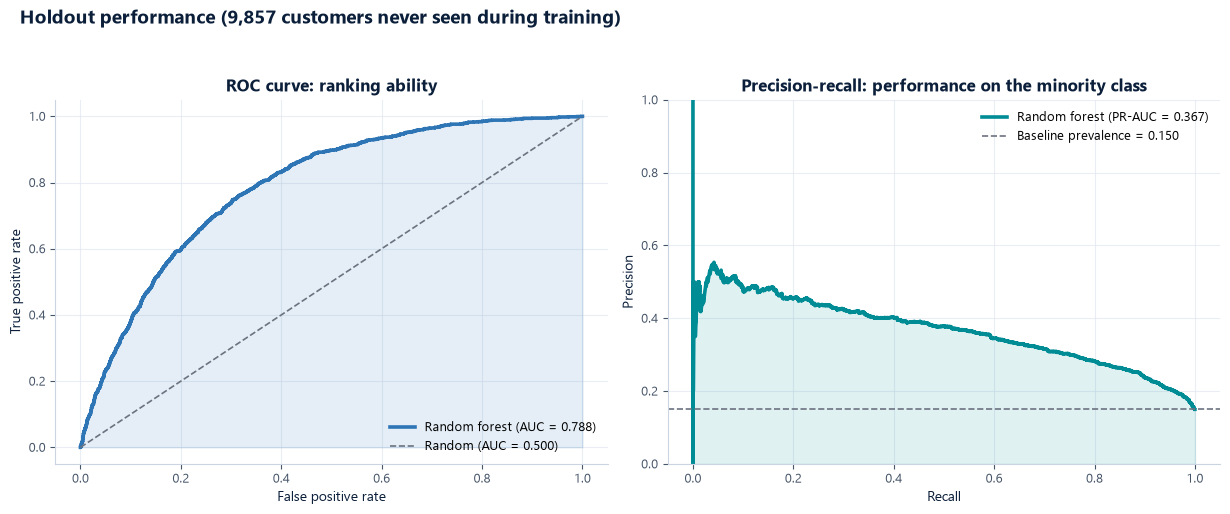

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2))

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax = axes[0]
ax.plot(fpr, tpr, color=MID_BLUE, linewidth=2.6, label=f"Random forest (AUC = {holdout['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1.2, label="Random (AUC = 0.500)")
ax.fill_between(fpr, tpr, alpha=0.12, color=MID_BLUE)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve: ranking ability")
ax.legend(loc="lower right", frameon=False, fontsize=9)
clean_axes(ax, "both")

precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_proba)
ax = axes[1]
ax.plot(
    recall_vals,
    precision_vals,
    color=TEAL,
    linewidth=2.6,
    label=f"Random forest (PR-AUC = {holdout['pr_auc']:.3f})",
)
ax.axhline(prevalence, color=GREY, linestyle="--", linewidth=1.2, label=f"Baseline prevalence = {prevalence:.3f}")
ax.fill_between(recall_vals, precision_vals, alpha=0.12, color=TEAL)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall: performance on the minority class")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", frameon=False, fontsize=9)
clean_axes(ax, "both")

fig.suptitle("Holdout performance (9,857 customers never seen during training)", x=0.02, ha="left", fontsize=14, fontweight="bold", color=NAVY)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "05_roc_pr_curves.png")

### Confusion matrix at the 0.5 threshold

The balanced class weights deliberately trade some precision for recall: the model flags more
customers, because missing a likely booker is expensive for a marketing team. The threshold is a
business choice and should be tuned to campaign capacity and contact cost.

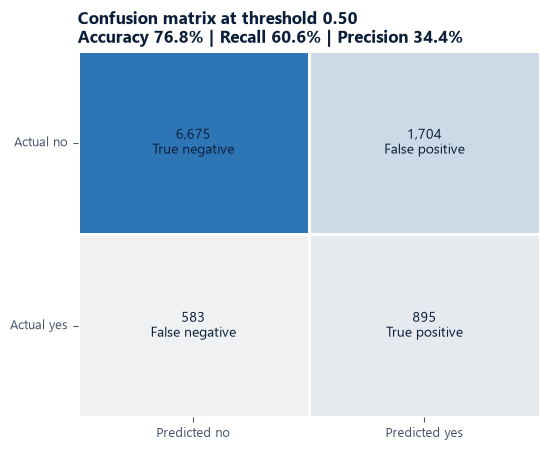

In [13]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(
    cm,
    annot=np.array(
        [
            [f"{tn:,}\nTrue negative", f"{fp:,}\nFalse positive"],
            [f"{fn:,}\nFalse negative", f"{tp:,}\nTrue positive"],
        ]
    ),
    fmt="",
    cmap=sns.light_palette(MID_BLUE, as_cmap=True),
    cbar=False,
    linewidths=2,
    linecolor="white",
    annot_kws={"fontsize": 10, "color": NAVY},
    ax=ax,
)
ax.set_xticklabels(["Predicted no", "Predicted yes"])
ax.set_yticklabels(["Actual no", "Actual yes"], rotation=0)
ax.set_title(f"Confusion matrix at threshold 0.50\nAccuracy {holdout['accuracy']:.1%} | Recall {holdout['recall']:.1%} | Precision {holdout['precision']:.1%}", loc="left")
fig.tight_layout()
save_figure(fig, "06_confusion_matrix.png")

### Targeting lift

For a marketing team, the most useful question is: *if we contact the top 10% of customers by
predicted probability, how many bookings do we capture?* This is more actionable than accuracy
or a single threshold.

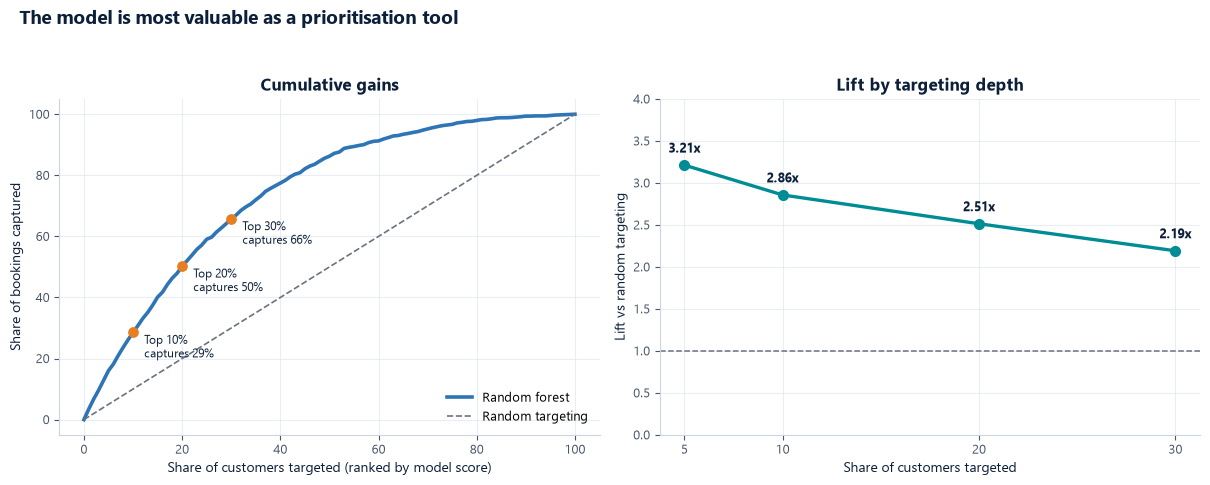

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.9))

# Cumulative gains
ax = axes[0]
fractions = np.linspace(0, 1, 101)
cumulative_capture = []
for f in fractions:
    k = max(1, int(len(y_test) * f))
    cumulative_capture.append(y_test_array[order[:k]].sum() / y_test_array.sum())
ax.plot(fractions * 100, np.array(cumulative_capture) * 100, color=MID_BLUE, linewidth=2.6, label="Random forest")
ax.plot([0, 100], [0, 100], color=GREY, linestyle="--", linewidth=1.2, label="Random targeting")
for f in (0.10, 0.20, 0.30):
    k = max(1, int(len(y_test) * f))
    capture = y_test_array[order[:k]].sum() / y_test_array.sum()
    ax.scatter([f * 100], [capture * 100], color=ORANGE, zorder=5, s=45)
    ax.annotate(
        f"Top {f:.0%}\ncaptures {capture:.0%}",
        (f * 100, capture * 100),
        textcoords="offset points",
        xytext=(8, -18),
        fontsize=8.5,
        color=NAVY,
    )
ax.set_xlabel("Share of customers targeted (ranked by model score)")
ax.set_ylabel("Share of bookings captured")
ax.set_title("Cumulative gains")
ax.legend(loc="lower right", frameon=False, fontsize=9)
clean_axes(ax, "both")

# Lift at top-k
ax = axes[1]
top = ranking[ranking["target_fraction"] <= 0.30]
ax.plot(top["target_fraction"] * 100, top["lift_vs_random"], marker="o", color=TEAL, linewidth=2.4, markersize=7)
for _, row in top.iterrows():
    ax.annotate(
        f"{row['lift_vs_random']:.2f}x",
        (row["target_fraction"] * 100, row["lift_vs_random"]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9,
        color=NAVY,
        fontweight="bold",
    )
ax.axhline(1, color=GREY, linestyle="--", linewidth=1.1)
ax.set_xlabel("Share of customers targeted")
ax.set_ylabel("Lift vs random targeting")
ax.set_title("Lift by targeting depth")
ax.set_xticks([5, 10, 20, 30])
ax.set_ylim(0, max(4.0, top["lift_vs_random"].max() + 0.6))
clean_axes(ax, "both")

fig.suptitle("The model is most valuable as a prioritisation tool", x=0.02, ha="left", fontsize=14, fontweight="bold", color=NAVY)
fig.tight_layout(rect=[0, 0, 1, 0.94])
save_figure(fig, "07_targeting_lift.png")

## 6. Which variables drive the model?

**Permutation importance** measures how much holdout ROC-AUC falls when a variable's values are
randomly shuffled. It is model-agnostic and, unlike the default impurity importance, does not
reward variables simply for having many possible split points.

Because `route` and `booking_origin` are target-encoded (one input column becomes one encoded
column), we permute the **raw** columns and let the whole pipeline re-encode them.

We report both individual and grouped importances. Grouping avoids understating related
variables such as departure hour + its sine/cosine transforms.

In [15]:
perm = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=12,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "importance_mean": perm.importances_mean,
            "importance_std": perm.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
importance["importance_pct"] = importance["importance_mean"] / importance["importance_mean"].sum()
importance

,feature,importance_mean,importance_std,importance_pct
0,booking_origin,0.112172,0.004297,0.500813
1,route,0.077690,0.003160,0.346860
2,length_of_stay,0.010928,0.001398,0.048790
3,sales_channel,0.006819,0.001035,0.030445
4,flight_duration,0.005165,0.000788,0.023062
5,purchase_lead,0.004596,0.000997,0.020521
6,extras_count,0.004237,0.000673,0.018918
7,wants_extra_baggage,0.002804,0.000643,0.012517
8,wants_preferred_seat,0.000951,0.000462,0.004245
9,wants_in_flight_meals,0.000442,0.000392,0.001975


In [16]:
FEATURE_LABELS = {
    "booking_origin": "Booking origin (country)",
    "route": "Flight route",
    "trip_type": "Trip type",
    "purchase_lead": "Purchase lead time",
    "flight_duration": "Flight duration",
    "sales_channel": "Sales channel",
    "length_of_stay": "Length of stay",
    "extras_count": "Number of extras",
    "wants_extra_baggage": "Extra baggage",
    "wants_preferred_seat": "Preferred seat",
    "wants_in_flight_meals": "In-flight meals",
    "flight_hour": "Departure hour",
    "flight_hour_sin": "Departure hour (sin)",
    "flight_hour_cos": "Departure hour (cos)",
    "flight_day_num": "Day of week",
    "is_weekend": "Weekend departure",
    "num_passengers": "Passengers",
}

GROUPS = {
    "Booking origin (country)": ["booking_origin"],
    "Flight route": ["route"],
    "Trip type": ["trip_type"],
    "Purchase lead time": ["purchase_lead"],
    "Flight duration": ["flight_duration"],
    "Sales channel": ["sales_channel"],
    "Length of stay": ["length_of_stay"],
    "Optional extras (all)": [
        "extras_count",
        "wants_extra_baggage",
        "wants_preferred_seat",
        "wants_in_flight_meals",
    ],
    "Departure hour (cyclical)": ["flight_hour", "flight_hour_sin", "flight_hour_cos"],
    "Flight day / weekend": ["flight_day_num", "is_weekend"],
    "Passengers": ["num_passengers"],
}


def grouped_permutation_importance(
    estimator,
    X_data: pd.DataFrame,
    y_data: pd.Series,
    groups: dict[str, list[str]],
    n_repeats: int = 12,
    random_state: int = RANDOM_STATE,
) -> pd.DataFrame:
    """Permutation importance for groups of columns, shuffling group members together."""
    rng = np.random.default_rng(random_state)
    baseline = roc_auc_score(y_data, estimator.predict_proba(X_data)[:, 1])
    records = []
    for group_name, columns in groups.items():
        drops = []
        for _ in range(n_repeats):
            X_permuted = X_data.copy()
            row_order = rng.permutation(len(X_data))
            permuted = X_data.iloc[row_order]
            for column in columns:
                X_permuted[column] = permuted[column].to_numpy()
            score = roc_auc_score(y_data, estimator.predict_proba(X_permuted)[:, 1])
            drops.append(baseline - score)
        records.append(
            {
                "driver": group_name,
                "importance_mean": float(np.mean(drops)),
                "importance_std": float(np.std(drops)),
            }
        )
    return pd.DataFrame(records).sort_values("importance_mean", ascending=False).reset_index(drop=True)


grouped_importance = grouped_permutation_importance(rf_pipeline, X_test, y_test, GROUPS)
grouped_importance["importance_pct"] = (
    grouped_importance["importance_mean"] / grouped_importance["importance_mean"].sum()
)
grouped_importance

,driver,importance_mean,importance_std,importance_pct
0,Booking origin (country),0.110073,0.005145,0.477033
1,Flight route,0.073437,0.003736,0.318259
2,Optional extras (all),0.018330,0.001902,0.079438
3,Length of stay,0.010957,0.001110,0.047484
4,Sales channel,0.006673,0.001038,0.028921
5,Flight duration,0.005299,0.001143,0.022965
6,Purchase lead time,0.004882,0.001021,0.021156
7,Departure hour (cyclical),0.000536,0.000975,0.002325
8,Flight day / weekend,0.000465,0.000400,0.002013
9,Trip type,0.000072,0.000094,0.000313


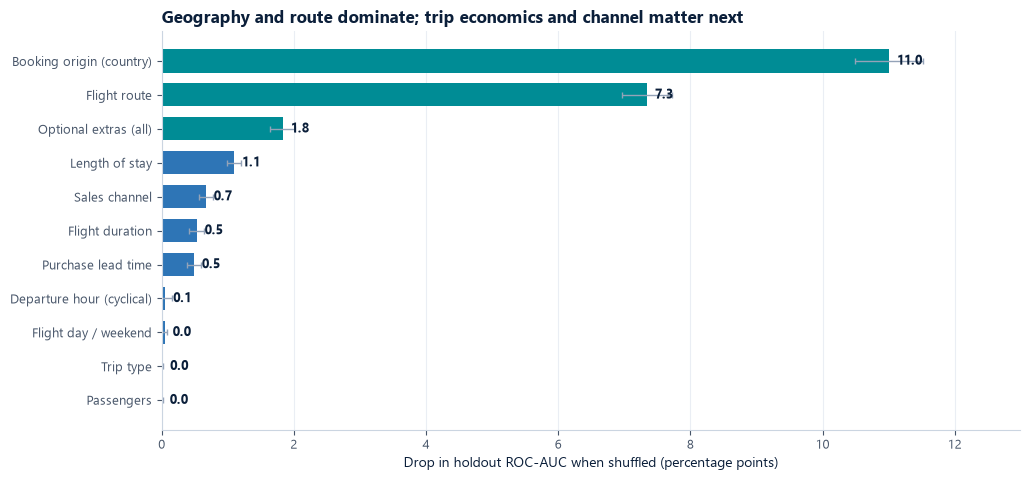

In [17]:
fig, ax = plt.subplots(figsize=(10.4, 4.9))
plot_data = grouped_importance.sort_values("importance_mean")
bar_colors = [MID_BLUE if i < len(plot_data) - 3 else TEAL for i in range(len(plot_data))]
bars = ax.barh(
    plot_data["driver"],
    plot_data["importance_mean"] * 100,
    xerr=plot_data["importance_std"] * 100,
    color=bar_colors,
    height=0.68,
    error_kw={"ecolor": "#94A3B8", "elinewidth": 1.0, "capsize": 2},
)
for bar, value in zip(bars, plot_data["importance_mean"] * 100):
    ax.text(
        bar.get_width() + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=9,
        color=NAVY,
        fontweight="bold",
    )
ax.set_xlabel("Drop in holdout ROC-AUC when shuffled (percentage points)")
ax.set_title("Geography and route dominate; trip economics and channel matter next", loc="left")
ax.set_xlim(0, max(plot_data["importance_mean"] * 100) * 1.18)
clean_axes(ax, "x")
fig.tight_layout()
save_figure(fig, "08_permutation_importance.png")

### Reading the importance chart

Shuffling **booking origin** or **route** causes the largest drop in ROC-AUC because they encode
very different conversion rates across markets (5% in Australia vs 35% in Malaysia). Trip type,
purchase lead time, flight duration, sales channel and length of stay follow. Optional extras
add a smaller but consistent signal.

This does **not** mean geography causes customers to book. It means the model can identify
segments with different historic conversion rates. Causal claims require experiments.

### Sensitivity check: is the model leaning on post-decision information?

The three "wants" fields may be recorded during checkout. To test how much the result depends on
them, we refit the same model without those fields and compare holdout ROC-AUC and PR-AUC.

In [18]:
SAFE_NUMERIC = [
    "num_passengers",
    "purchase_lead",
    "length_of_stay",
    "flight_hour",
    "flight_hour_sin",
    "flight_hour_cos",
    "flight_duration",
    "flight_day_num",
    "is_weekend",
]

no_extras_pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            ColumnTransformer(
                transformers=[
                    ("numeric", "passthrough", SAFE_NUMERIC),
                    (
                        "categorical",
                        TargetEncoder(
                            target_type="binary",
                            smooth="auto",
                            cv=5,
                            random_state=RANDOM_STATE,
                        ),
                        CATEGORICAL_FEATURES,
                    ),
                ]
            ),
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=N_ESTIMATORS,
                min_samples_leaf=MIN_SAMPLES_LEAF,
                max_features="sqrt",
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
no_extras_pipeline.fit(X_train[SAFE_NUMERIC + CATEGORICAL_FEATURES], y_train)
no_extras_proba = no_extras_pipeline.predict_proba(
    X_test[SAFE_NUMERIC + CATEGORICAL_FEATURES]
)[:, 1]

sensitivity = pd.DataFrame(
    {
        "Model": ["With optional-extra fields", "Without optional-extra fields"],
        "Holdout ROC-AUC": [
            holdout["roc_auc"],
            roc_auc_score(y_test, no_extras_proba),
        ],
        "Holdout PR-AUC": [
            holdout["pr_auc"],
            average_precision_score(y_test, no_extras_proba),
        ],
    }
)
sensitivity

,Model,Holdout ROC-AUC,Holdout PR-AUC
0,With optional-extra fields,0.788271,0.366976
1,Without optional-extra fields,0.781165,0.352156


## 7. Cross-validation stability

The five folds are consistent, so the holdout result is not a lucky split.

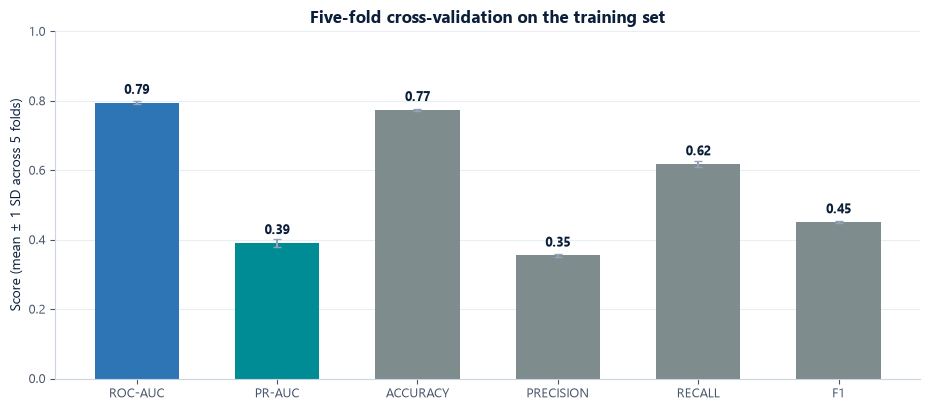

In [19]:
fig, ax = plt.subplots(figsize=(9.4, 4.2))
metrics_to_plot = ["roc_auc", "pr_auc", "accuracy", "precision", "recall", "f1"]
means = [cv_results[f"test_{m}"].mean() for m in metrics_to_plot]
errors = [cv_results[f"test_{m}"].std() for m in metrics_to_plot]
colors_bar = [MID_BLUE, TEAL, "#7F8C8D", "#7F8C8D", "#7F8C8D", "#7F8C8D"]
bars = ax.bar(
    [m.replace("_", "-").upper() for m in metrics_to_plot],
    means,
    yerr=errors,
    color=colors_bar,
    width=0.6,
    error_kw={"ecolor": "#94A3B8", "capsize": 3},
)
for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.025, f"{value:.2f}", ha="center", fontsize=9, color=NAVY, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Score (mean ± 1 SD across 5 folds)")
ax.set_title("Five-fold cross-validation on the training set")
clean_axes(ax)
fig.tight_layout()
save_figure(fig, "09_cv_metrics.png")

## 8. Findings and recommendations

### How predictive is the data?

- Holdout **ROC-AUC ≈ 0.79**: the model ranks a random booker above a random non-booker about
  79% of the time. This is useful discrimination, but not a certain individual classifier.
- **PR-AUC ≈ 0.38** against a 0.15 base rate: roughly **2.5x** the no-skill baseline.
- If the marketing team contacts the **top 10%** of customers, the model captures a
  disproportionate share of bookings and delivers around **2-3x lift** over random contact.
- **Accuracy is a trap here.** A model that predicts "no booking" for everyone scores 85%, yet is
  useless. The balanced model intentionally accepts lower accuracy to find more bookers.

### What drives bookings?

1. **Market of origin** is the largest driver, followed by **route**. Conversion ranges from
   ~5% (Australia/New Zealand) to 35% (Malaysia), so campaign targeting should be market-aware.
2. **Trip economics**: round trips convert far more than one-way/circle trips; short breaks
   (4-7 days) convert at 19.5% vs 10.1% for 15-30 day stays.
3. **Channel and lead time**: Internet converts at 15.5% vs 11.0% for mobile; late bookers
   (0-7 days) convert at 17.3% vs 13.5-14.6% for longer lead times.
4. **Optional extras**: customers selecting all three extras convert at 18.6% vs 10.7% for none.
   This is a useful intent signal **if** the fields are captured before payment.

### Recommended actions

- Use the model as a **ranked lead list** for marketing, not as an automatic accept/reject rule.
- Prioritise high-converting origins/routes and short-break itineraries, and promote extras
  during the booking journey.
- Set the operating threshold from campaign capacity and contact cost; monitor precision at the
  chosen targeting depth.
- A/B test the campaign against random targeting to measure incremental bookings, not just
  correlation.
- Collect price, seasonality/date, repeat-customer and abandoned-search data. These are likely to
  add more signal than further tuning of the current 14 columns.

### Limitations

- Observational data: importance is predictive, not causal.
- No price, date/season or customer-history fields.
- 719 duplicate rows removed; if they are genuine separate customers, the effective sample is
  slightly larger.
- The optional-extra fields may be recorded late in the funnel; confirm their timing.
- The model is trained on one period and one market mix. Retrain and monitor drift before reuse.

## 9. Save artefacts

The slide deck is generated from `outputs/metrics.json`, `outputs/feature_importance.csv` and the
figures in `outputs/figures/`.

In [20]:
importance.to_csv(OUT_DIR / "feature_importance.csv", index=False)
grouped_importance.to_csv(OUT_DIR / "grouped_feature_importance.csv", index=False)
ranking.to_csv(OUT_DIR / "targeting_lift.csv", index=False)
cv_table.to_csv(OUT_DIR / "cv_metrics.csv", index=False)
comparison.to_csv(OUT_DIR / "model_comparison.csv", index=False)
sensitivity.to_csv(OUT_DIR / "extras_sensitivity.csv", index=False)

metrics_payload = {
    "dataset": {
        "raw_rows": int(len(raw)),
        "rows_after_dedup": int(len(booking)),
        "duplicates_removed": int(raw.duplicated().sum()),
        "columns": int(raw.shape[1]),
        "positive_rate": float(y.mean()),
        "train_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
    },
    "model": {
        "type": "RandomForestClassifier",
        "n_estimators": N_ESTIMATORS,
        "min_samples_leaf": MIN_SAMPLES_LEAF,
        "class_weight": "balanced_subsample",
        "categorical_encoding": "out-of-fold target encoding",
        "n_features": len(FEATURES),
        "cv_folds": 5,
        "fit_seconds": round(fit_seconds, 1),
    },
    "cv": {
        metric: {
            "mean": float(cv_results[f"test_{metric}"].mean()),
            "std": float(cv_results[f"test_{metric}"].std()),
        }
        for metric in SCORING
    },
    "holdout": holdout,
    "ranking": ranking.to_dict(orient="records"),
    "comparison": comparison.to_dict(orient="records"),
    "sensitivity": sensitivity.to_dict(orient="records"),
    "top_drivers": grouped_importance.head(8).to_dict(orient="records"),
    "figures": sorted(path.name for path in FIG_DIR.glob("*.png")),
}

with open(OUT_DIR / "metrics.json", "w", encoding="utf-8") as handle:
    json.dump(metrics_payload, handle, indent=2)

print("Saved artefacts:")
for path in sorted(OUT_DIR.glob("*")):
    if path.is_file():
        print(f"  - {path.name}")
print(f"  - figures/: {len(list(FIG_DIR.glob('*.png')))} charts")

Saved artefacts:
  - customer_booking_features.csv
  - cv_metrics.csv
  - extras_sensitivity.csv
  - feature_importance.csv
  - grouped_feature_importance.csv
  - metrics.json
  - model_comparison.csv
  - slide_preview.png
  - targeting_lift.csv
  - figures/: 10 charts
